# **SmartFlow Machine Learning-Based Traffic Optimization for Autonomous Vehicles**

In [ ]:

# Import necessary libraries
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns




In [ ]:
# Reading the CSV file
file_path = "/content/drive/MyDrive/Colab Notebooks/dataset/csv/labels_train.csv"
df_traffic = pd.read_csv(file_path)


# Inspecting the Data

In [ ]:
df_traffic.head()

,frame,xmin,xmax,ymin,ymax,class_id
0,1478019952686311006.jpg,237,251,143,155,1
1,1478019952686311006.jpg,437,454,120,186,3
2,1478019953180167674.jpg,218,231,146,158,1
3,1478019953689774621.jpg,171,182,141,154,2
4,1478019953689774621.jpg,179,191,144,155,1


In [ ]:
df_traffic.tail()

,frame,xmin,xmax,ymin,ymax,class_id
132401,1479506176491553178.jpg,166,186,139,156,1
132402,1479506176491553178.jpg,182,204,142,153,1
132403,1479506176491553178.jpg,239,261,139,155,1
132404,1479506176491553178.jpg,259,280,139,157,1
132405,1479506176491553178.jpg,284,324,137,168,1


In [ ]:
df_traffic.shape

(132406, 6)

In [ ]:
df_traffic.shape[0]

132406

In [ ]:
df_traffic.shape[1]

6

In [ ]:
df_traffic.columns

Index(['frame', 'xmin', 'xmax', 'ymin', 'ymax', 'class_id'], dtype='object')

In [ ]:
df_traffic.dtypes

,0
frame,object
xmin,int64
xmax,int64
ymin,int64
ymax,int64
class_id,int64


In [ ]:
df_traffic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 132406 entries, 0 to 132405
Data columns (total 6 columns):
 #   Column    Non-Null Count   Dtype 
---  ------    --------------   ----- 
 0   frame     132406 non-null  object
 1   xmin      132406 non-null  int64 
 2   xmax      132406 non-null  int64 
 3   ymin      132406 non-null  int64 
 4   ymax      132406 non-null  int64 
 5   class_id  132406 non-null  int64 
dtypes: int64(5), object(1)
memory usage: 6.1+ MB


In [ ]:
df_traffic.describe()

,xmin,xmax,ymin,ymax,class_id
count,132406.000000,132406.000000,132406.000000,132406.000000,132406.000000
mean,202.112223,235.400118,133.525376,162.240148,1.624692
std,114.647213,116.401491,20.508451,28.585448,1.269443
min,0.000000,3.000000,0.000000,0.000000,1.000000
25%,118.000000,150.000000,131.000000,152.000000,1.000000
50%,200.000000,224.000000,139.000000,160.000000,1.000000
75%,280.000000,312.000000,143.000000,171.000000,1.000000
max,475.000000,479.000000,275.000000,299.000000,5.000000


#  Data Cleaning

In [ ]:
cleaned_df_traffic = df_traffic[['xmin', 'xmax', 'ymin', 'ymax', 'class_id']]

<Axes: >

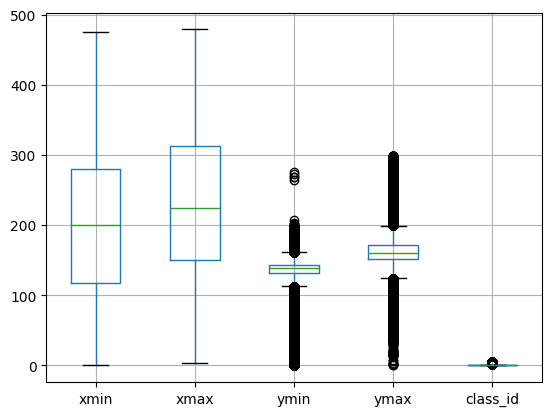

In [ ]:
#oulier Analysis
cleaned_df_traffic.boxplot()

In [ ]:
cleaned_df_traffic.isnull().sum()

,0
xmin,0
xmax,0
ymin,0
ymax,0
class_id,0


In [ ]:
df_traffic = cleaned_df_traffic.dropna()

In [ ]:


df_traffic['width'] = df_traffic['xmax'] - df_traffic['xmin']
df_traffic['height'] = df_traffic['ymax'] - df_traffic['ymin']





<ipython-input-18-f1aed2a0550b>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='class_id', data=df_traffic, palette='viridis')


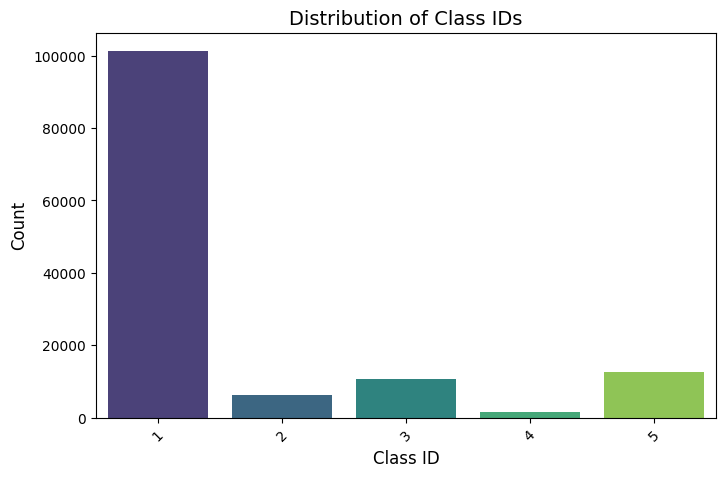

In [ ]:
# Visualization 1: Distribution of Class IDs
plt.figure(figsize=(8, 5))
sns.countplot(x='class_id', data=df_traffic, palette='viridis')
plt.title('Distribution of Class IDs', fontsize=14)
plt.xlabel('Class ID', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.xticks(rotation=45)
plt.show()

<ipython-input-19-56bb59a5307c>:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


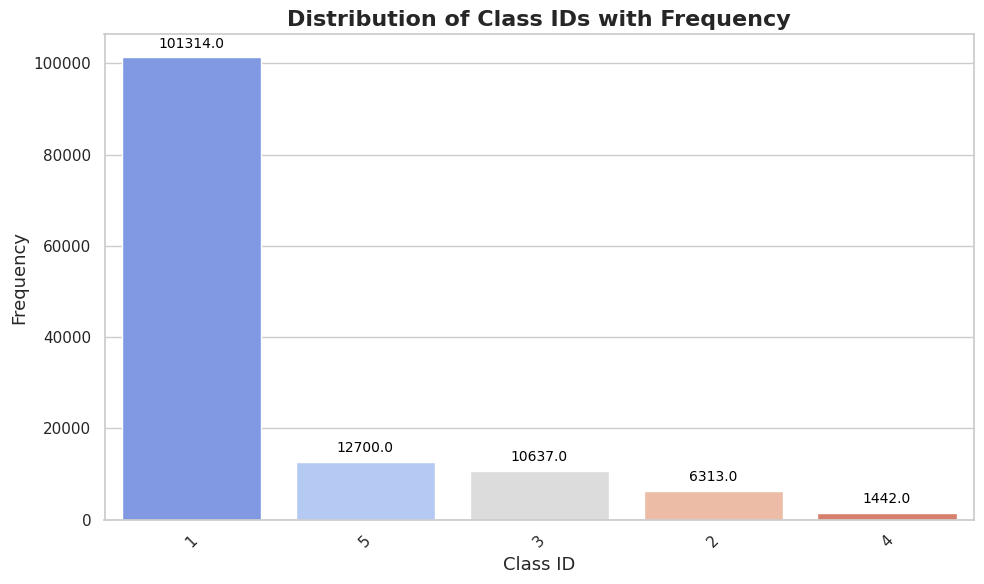

In [ ]:

import seaborn as sns
sns.set(style="whitegrid")

# Create the plot
plt.figure(figsize=(10, 6))
ax = sns.countplot(
    x='class_id',
    data=df_traffic,
    palette='coolwarm',
    order=df_traffic['class_id'].value_counts().index
)

plt.title('Distribution of Class IDs with Frequency', fontsize=16, fontweight='bold')
plt.xlabel('Class ID', fontsize=13)
plt.ylabel('Frequency', fontsize=13)


plt.xticks(rotation=45)


for p in ax.patches:
    ax.annotate(f'{p.get_height()}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=10, color='black', xytext=(0, 5),
                textcoords='offset points')

plt.tight_layout()
plt.show()


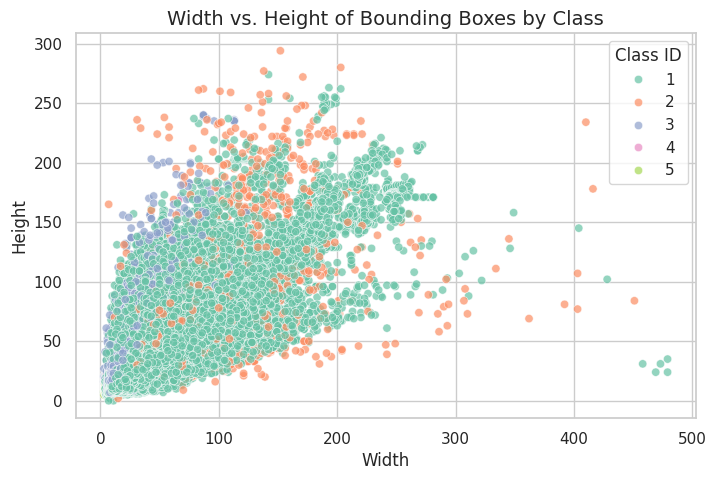

In [ ]:
# Visualization 2: Width vs. Height of Bounding Boxes by Class
plt.figure(figsize=(8, 5))
sns.scatterplot(
    x='width',
    y='height',
    hue='class_id',
    data=df_traffic,
    palette='Set2',
    alpha=0.7
)
plt.title('Width vs. Height of Bounding Boxes by Class', fontsize=14)
plt.xlabel('Width', fontsize=12)
plt.ylabel('Height', fontsize=12)
plt.legend(title='Class ID')
plt.show()

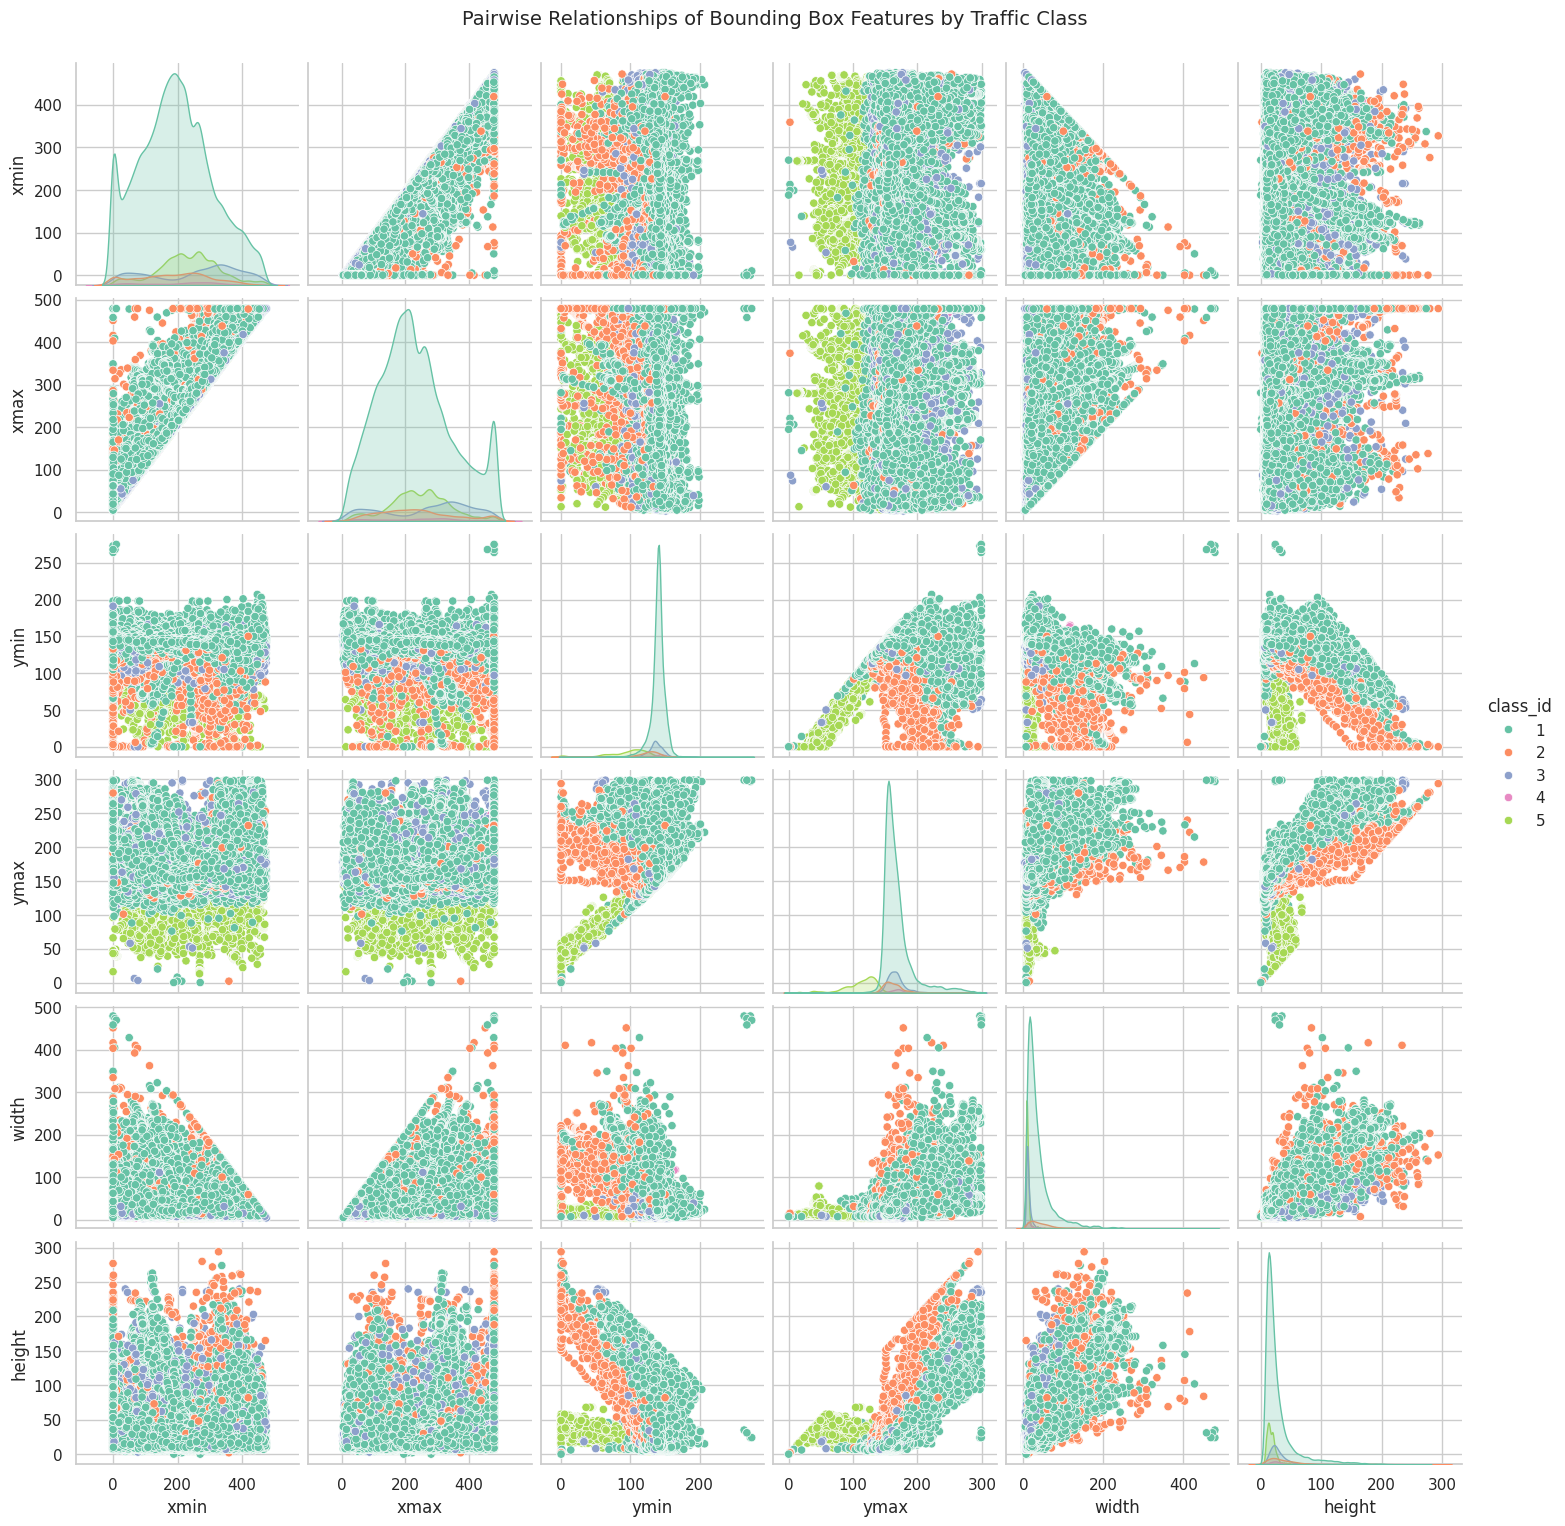

In [ ]:
sns.pairplot(df_traffic, hue='class_id', palette='Set2')
plt.suptitle('Pairwise Relationships of Bounding Box Features by Traffic Class', y=1.02, fontsize=14)
plt.show()

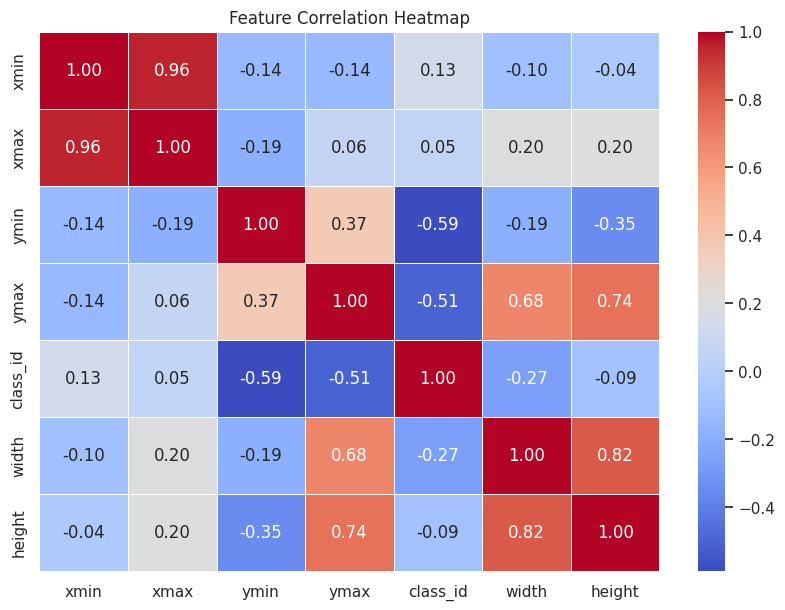

In [ ]:
# Compute correlation matrix
numeric_data = df_traffic.select_dtypes(include=["float64", "int64"])


if not numeric_data.empty:
    plt.figure(figsize=(10, 7))
    sns.heatmap(numeric_data.corr(), annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
    plt.title("Feature Correlation Heatmap")
    plt.show()
else:
    print("No numeric columns available for correlation heatmap.")

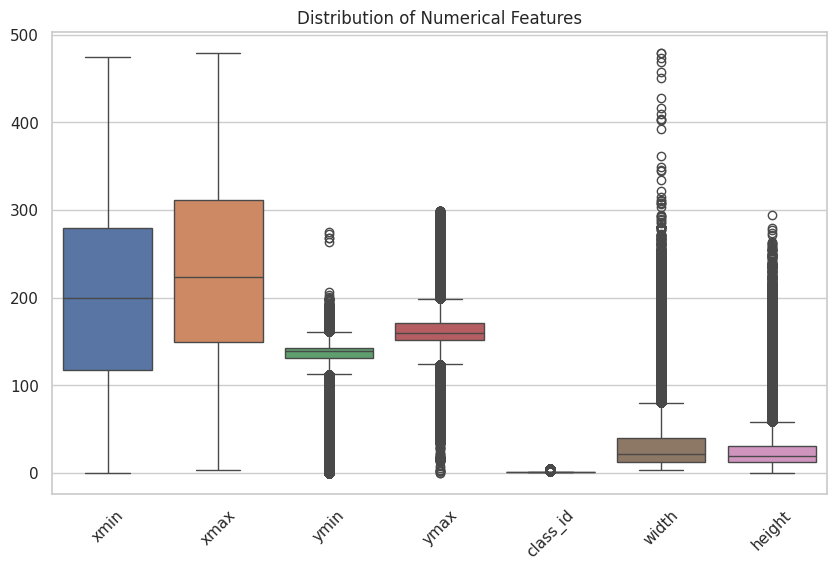

In [ ]:
plt.figure(figsize=(10, 6))

num_cols = df_traffic.select_dtypes(include=["float64", "int64"]).columns
sns.boxplot(data=df_traffic[num_cols])
plt.title("Distribution of Numerical Features")
plt.xticks(rotation=45)
plt.show()

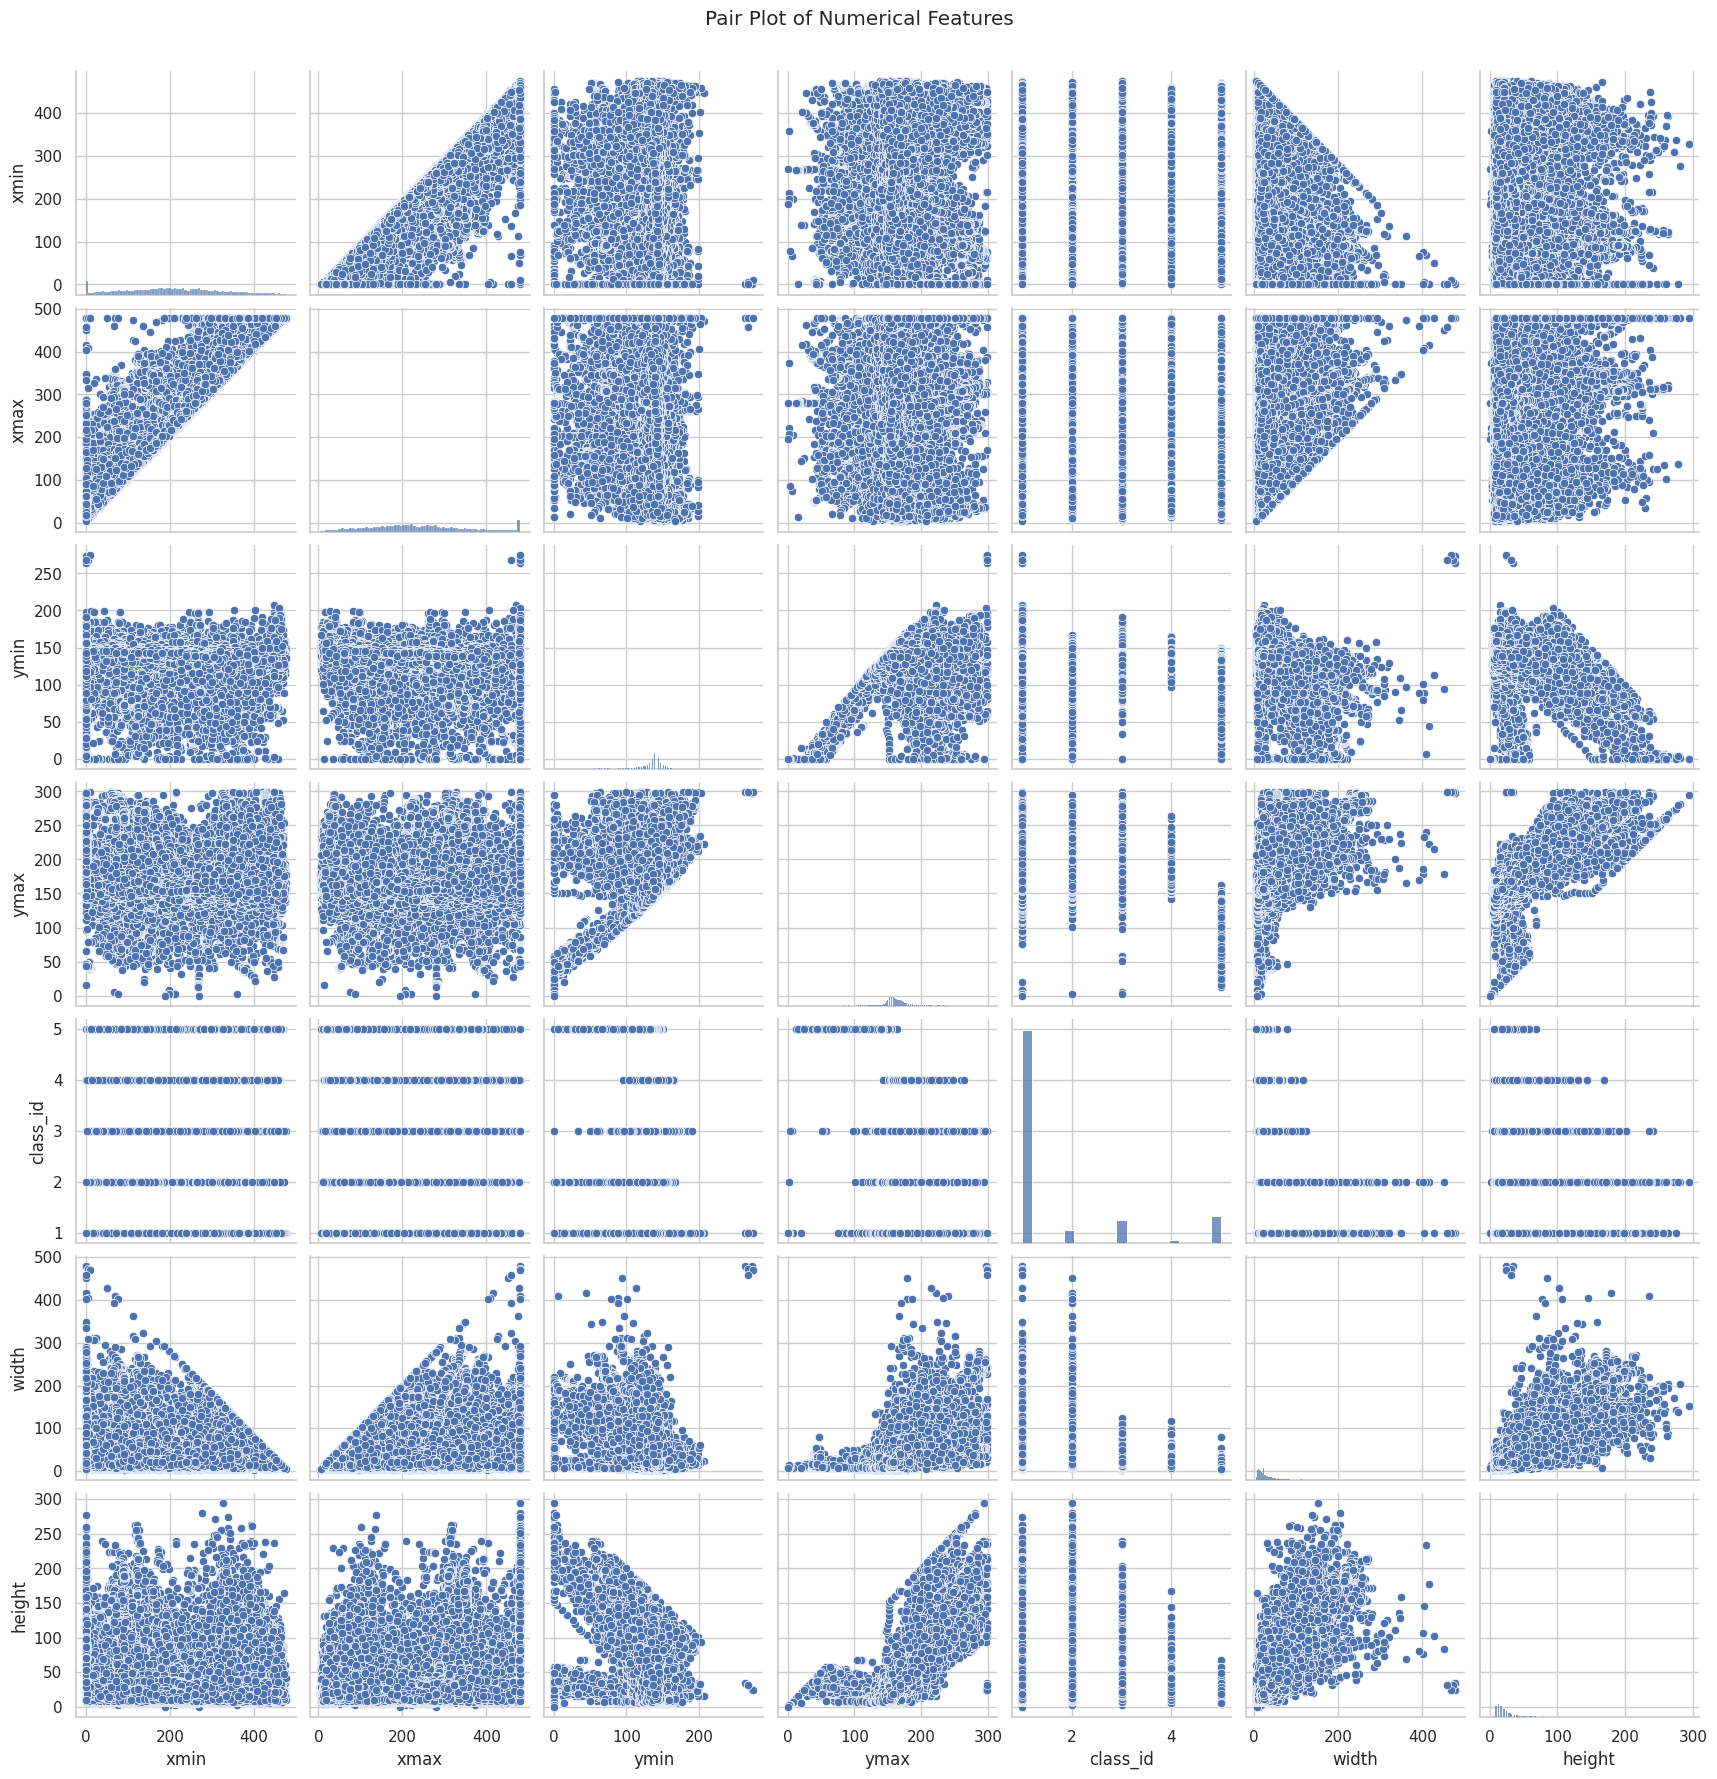

In [ ]:
sns.pairplot(df_traffic[num_cols])
plt.suptitle("Pair Plot of Numerical Features", y=1.02)
plt.show()

# Model Development

In [ ]:
# Select features (bounding box coordinates) and target (class_id)
X = df_traffic[['xmin', 'xmax', 'ymin', 'ymax']]
y = df_traffic['class_id']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Initialize and train the Random Forest model
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Predict on the test data
y_pred = model.predict(X_test)

# Evaluation
print("Classification Report:\n", classification_report(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

Classification Report:
               precision    recall  f1-score   support

           1       0.94      0.98      0.96     30378
           2       0.76      0.51      0.61      1899
           3       0.88      0.76      0.81      3161
           4       0.73      0.31      0.44       442
           5       0.94      0.96      0.95      3842

    accuracy                           0.93     39722
   macro avg       0.85      0.70      0.75     39722
weighted avg       0.92      0.93      0.92     39722

Confusion Matrix:
 [[29704   268   201    17   188]
 [  903   975    12     0     9]
 [  694    26  2390    33    18]
 [  189     0   114   139     0]
 [  142    10    12     1  3677]]


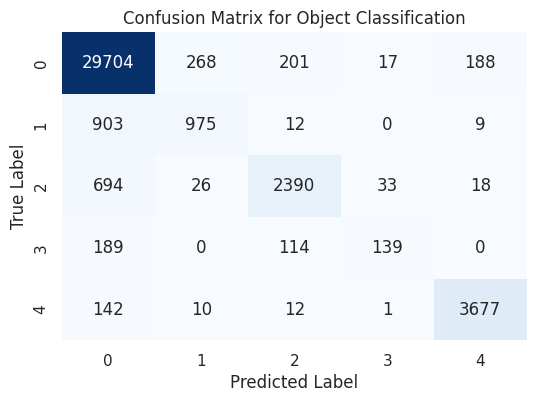

In [ ]:
# Visualization: Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues", cbar=False)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix for Object Classification")
plt.show()

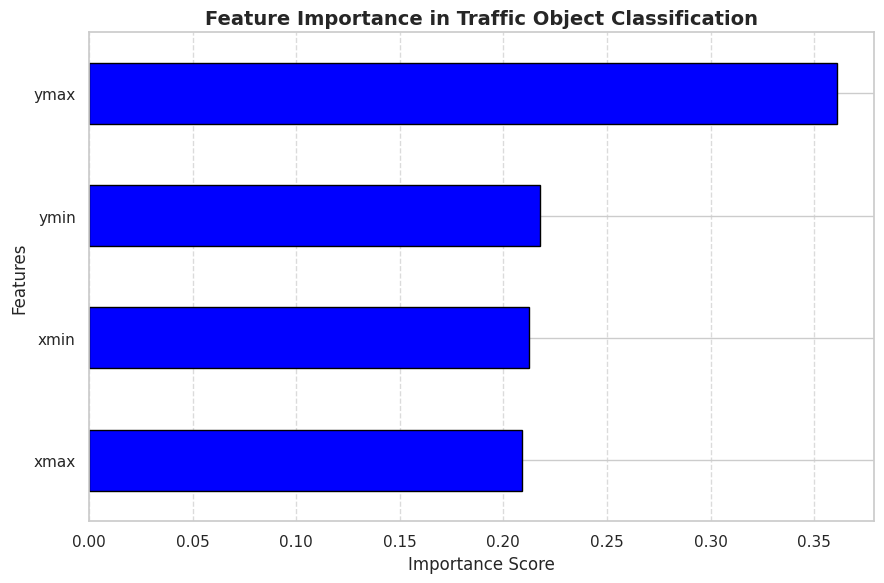

In [ ]:
# Feature Importance
feature_importances = pd.Series(model.feature_importances_, index=X.columns)

plt.figure(figsize=(9, 6))
feature_importances.sort_values().plot(kind='barh', color='blue', edgecolor='black')

plt.title("Feature Importance in Traffic Object Classification", fontsize=14, weight='bold')
plt.xlabel("Importance Score", fontsize=12)
plt.ylabel("Features", fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Model Comparision

Classification Report for Random Forest:
               precision    recall  f1-score   support

           1       0.94      0.98      0.96     30378
           2       0.76      0.51      0.61      1899
           3       0.88      0.76      0.81      3161
           4       0.73      0.31      0.44       442
           5       0.94      0.96      0.95      3842

    accuracy                           0.93     39722
   macro avg       0.85      0.70      0.75     39722
weighted avg       0.92      0.93      0.92     39722

Confusion Matrix for Random Forest:
 [[29704   268   201    17   188]
 [  903   975    12     0     9]
 [  694    26  2390    33    18]
 [  189     0   114   139     0]
 [  142    10    12     1  3677]]


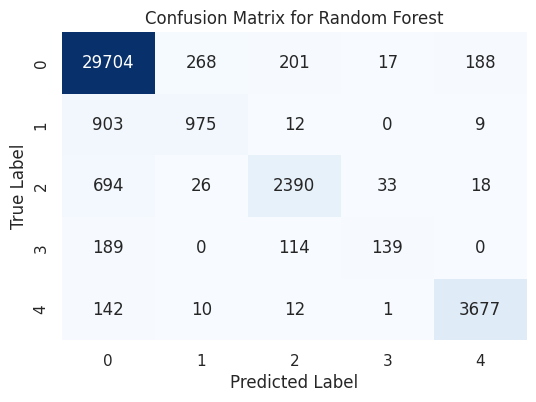

Classification Report for KNN:
               precision    recall  f1-score   support

           1       0.94      0.98      0.96     30378
           2       0.77      0.48      0.59      1899
           3       0.86      0.79      0.83      3161
           4       0.66      0.34      0.45       442
           5       0.96      0.96      0.96      3842

    accuracy                           0.93     39722
   macro avg       0.84      0.71      0.76     39722
weighted avg       0.93      0.93      0.93     39722

Confusion Matrix for KNN:
 [[29717   256   239    40   126]
 [  964   920     9     0     6]
 [  588    13  2500    35    25]
 [  166     1   125   150     0]
 [  115     4    20     1  3702]]


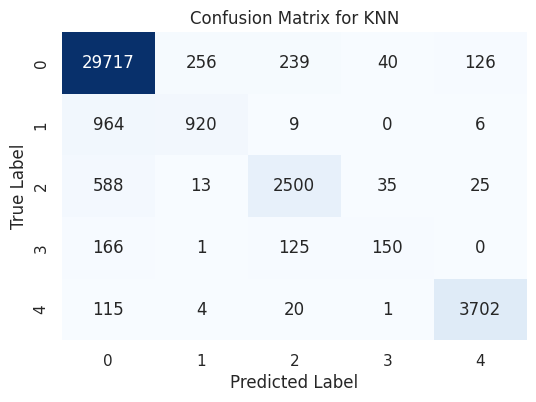

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

# Select features (bounding box coordinates) and target (class_id)
X = df_traffic[['xmin', 'xmax', 'ymin', 'ymax']]
y = df_traffic['class_id']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

models = {
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'KNN': KNeighborsClassifier()
}

results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    results[name] = accuracy

    # Print classification report and confusion matrix for each model
    print(f"Classification Report for {name}:\n", classification_report(y_test, y_pred))
    print(f"Confusion Matrix for {name}:\n", confusion_matrix(y_test, y_pred))

    # Visualization: Confusion Matrix for each model
    plt.figure(figsize=(6, 4))
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues", cbar=False)
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.title(f"Confusion Matrix for {name}")
    plt.show()


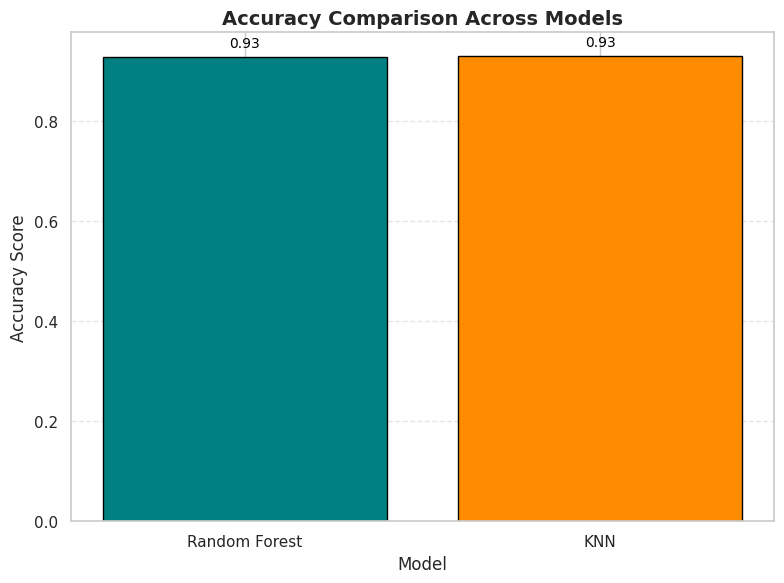

In [ ]:
# Plot Comparison of Accuracy
plt.figure(figsize=(8, 6))


colors = ['teal', 'darkorange']

bars = plt.bar(results.keys(), results.values(), color=colors, edgecolor='black')
plt.title("Accuracy Comparison Across Models", fontsize=14, weight='bold')
plt.xlabel("Model", fontsize=12)
plt.ylabel("Accuracy Score", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)

for bar in bars:
    height = bar.get_height()
    plt.annotate(f'{height:.2f}',
                 xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 5),  # 5 points vertical offset
                 textcoords="offset points",
                 ha='center', va='bottom', fontsize=10, color='black')

plt.tight_layout()
plt.show()


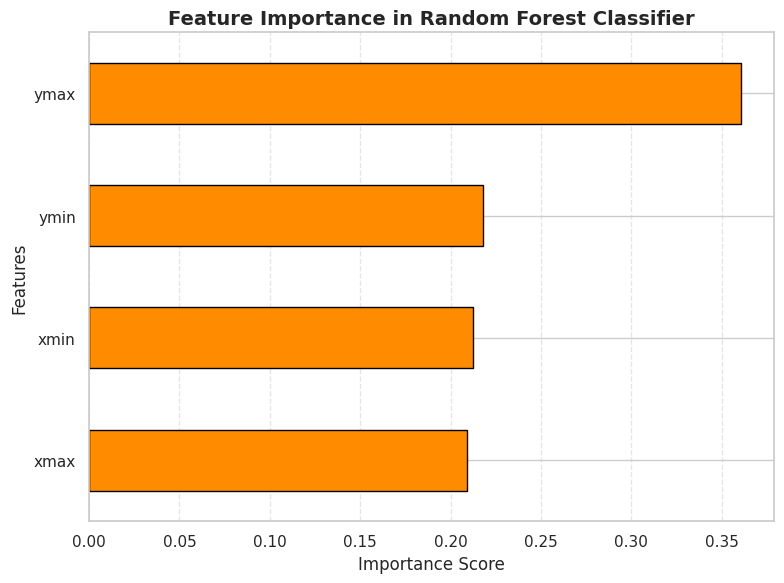

In [ ]:
# Feature Importance for Random Forest
feature_importances = pd.Series(models['Random Forest'].feature_importances_, index=X.columns)
plt.figure(figsize=(8, 6))
feature_importances.sort_values().plot(kind='barh', color='darkorange', edgecolor='black')
plt.title("Feature Importance in Random Forest Classifier", fontsize=14, weight='bold')
plt.xlabel("Importance Score", fontsize=12)
plt.ylabel("Features", fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

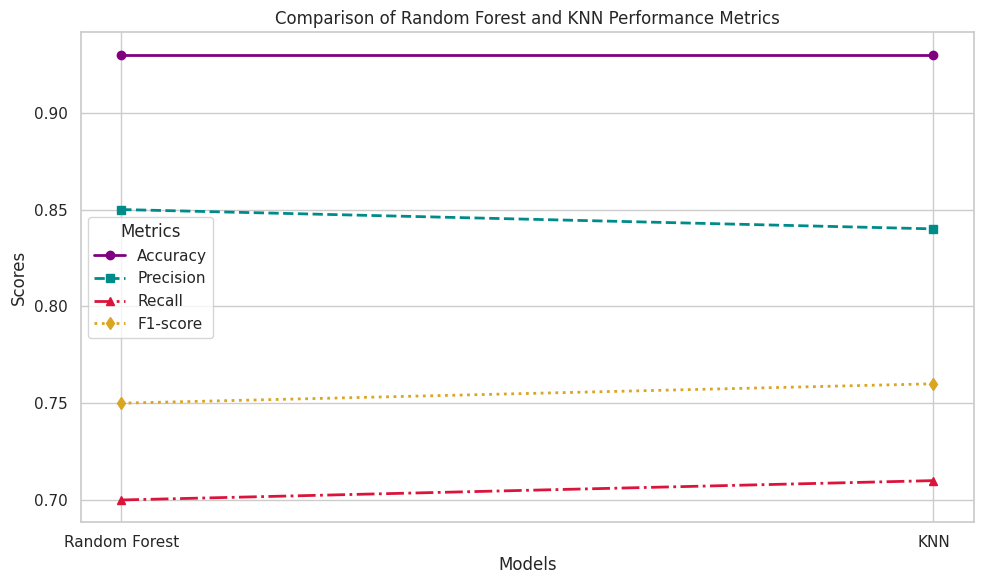

In [ ]:
import matplotlib.pyplot as plt

models = ['Random Forest', 'KNN']
accuracy = [0.93, 0.93]
precision = [0.85, 0.84]
recall = [0.70, 0.71]
f1_score = [0.75, 0.76]


plt.figure(figsize=(10, 6))

plt.plot(models, accuracy, marker='o', label='Accuracy', color='purple', linestyle='-', linewidth=2)
plt.plot(models, precision, marker='s', label='Precision', color='darkcyan', linestyle='--', linewidth=2)
plt.plot(models, recall, marker='^', label='Recall', color='crimson', linestyle='-.', linewidth=2)
plt.plot(models, f1_score, marker='d', label='F1-score', color='goldenrod', linestyle=':', linewidth=2)

plt.xlabel('Models')
plt.ylabel('Scores')
plt.title('Comparison of Random Forest and KNN Performance Metrics')
plt.legend(title='Metrics')
plt.grid(True)
plt.tight_layout()
plt.show()